# Advanced Evaluation of the Packaged Best Model

This notebook evaluates robustness, test-time augmentation (TTA), confidence calibration, and selective prediction. TTA and calibration are selected exclusively on validation data; the held-out test split is evaluated once. Evaluation cannot guarantee or create a perfect model.

## 1. Setup and integrity checks

In [1]:
import hashlib
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from PIL import Image, ImageEnhance, ImageOps, UnidentifiedImageError
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
)
from ultralytics import YOLO, __version__ as ultralytics_version

dataset_candidates = [
    Path("../datasets/shoe_brands_preprocessed").resolve(),
    Path("modeling/datasets/shoe_brands_preprocessed").resolve(),
    Path("datasets/shoe_brands_preprocessed").resolve(),
]
DATASET_ROOT = next((path for path in dataset_candidates if path.is_dir()), None)
if DATASET_ROOT is None:
    raise FileNotFoundError(f"Dataset not found. Checked: {dataset_candidates}")
MODELING_ROOT = DATASET_ROOT.parents[1]
PROJECT_ROOT = MODELING_ROOT.parent
MODEL_PACKAGE = PROJECT_ROOT / "model" / "2026-11-16_improvement-best"
MODEL_PATH = MODEL_PACKAGE / "model.pt"
METADATA_PATH = MODEL_PACKAGE / "metadata.json"
OUTPUT_ROOT = MODELING_ROOT / "runs" / "training" / "advanced_evaluation"
EXPECTED_CLASSES = ["adidas", "converse", "nike"]
EXPECTED_COUNTS = {"val": 55, "test": 27}
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
IMAGE_SIZE = 224
DEVICE = 0 if torch.cuda.is_available() else "cpu"
ECE_BINS = 10
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

if not MODEL_PATH.is_file() or not METADATA_PATH.is_file():
    raise FileNotFoundError(f"Incomplete model package: {MODEL_PACKAGE}")
metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))
actual_sha256 = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest().upper()
expected_sha256 = metadata["artifacts"]["model.pt"]["sha256"].upper()
if actual_sha256 != expected_sha256:
    raise RuntimeError("Model checksum does not match metadata.")
model = YOLO(str(MODEL_PATH))
if [model.names[index] for index in sorted(model.names)] != EXPECTED_CLASSES:
    raise ValueError(f"Unexpected model classes: {model.names}")
print(f"Model: {MODEL_PATH}")
print(f"Device: {DEVICE}")
print(f"Checksum verified: {actual_sha256}")

Model: C:\my-project\shoe-brand-classifier\model\2026-11-16_improvement-best\model.pt
Device: cpu
Checksum verified: 8FF16BFEA73C93EA22AAAA7D2D0EE182AA7ED73C3A799C9B88D9DBB9FFAF13CA


## 2. Validate evaluation data and split integrity

In [2]:
def split_paths(split_name: str) -> list[Path]:
    return sorted(
        path for path in (DATASET_ROOT / split_name).rglob("*")
        if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS
    )

audit_records = []
corrupt_images = []
for split_name, expected_per_class in EXPECTED_COUNTS.items():
    for class_name in EXPECTED_CLASSES:
        class_paths = sorted(
            path for path in (DATASET_ROOT / split_name / class_name).iterdir()
            if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS
        )
        if len(class_paths) != expected_per_class:
            raise ValueError(f"Expected {expected_per_class} images in {split_name}/{class_name}; found {len(class_paths)}.")
        for image_path in class_paths:
            try:
                with Image.open(image_path) as image:
                    image.verify()
            except (OSError, UnidentifiedImageError) as error:
                corrupt_images.append({"path": str(image_path), "error": str(error)})
            audit_records.append({"split": split_name, "class_name": class_name, "path": str(image_path), "sha256": hashlib.sha256(image_path.read_bytes()).hexdigest()})
audit_frame = pd.DataFrame(audit_records)
duplicates = audit_frame[audit_frame.duplicated("sha256", keep=False)]
if corrupt_images:
    raise RuntimeError(f"Corrupt images: {corrupt_images}")
if not duplicates.empty:
    display(duplicates.sort_values("sha256"))
    raise RuntimeError("Exact duplicate leakage found between validation and test splits.")
display(audit_frame.groupby(["split", "class_name"]).size().unstack(fill_value=0))
print(f"Evaluation audit passed for {len(audit_frame)} images.")

class_name,adidas,converse,nike
split,,,
test,27,27,27
val,55,55,55


Evaluation audit passed for 246 images.


## 3. Prediction, TTA, and metric helpers

In [3]:
CLASS_TO_INDEX = {name: index for index, name in enumerate(EXPECTED_CLASSES)}

def load_rgb(image_path: Path) -> Image.Image:
    with Image.open(image_path) as image:
        return image.convert("RGB")

def center_crop_resize(image: Image.Image, crop_fraction: float = 0.9) -> Image.Image:
    width, height = image.size
    crop_width, crop_height = int(width * crop_fraction), int(height * crop_fraction)
    left, top = (width - crop_width) // 2, (height - crop_height) // 2
    return image.crop((left, top, left + crop_width, top + crop_height)).resize((width, height))

TRANSFORMS = {
    "original": lambda image: image,
    "horizontal_flip": ImageOps.mirror,
    "brightness_up": lambda image: ImageEnhance.Brightness(image).enhance(1.1),
    "contrast_up": lambda image: ImageEnhance.Contrast(image).enhance(1.1),
    "center_crop": center_crop_resize,
}
TTA_STRATEGIES = {
    "single_pass": ["original"],
    "flip_tta": ["original", "horizontal_flip"],
    "light_tta": ["original", "horizontal_flip", "brightness_up", "contrast_up", "center_crop"],
}

def predict_probabilities(images: list[Image.Image]) -> tuple[np.ndarray, float]:
    arrays = [np.asarray(image) for image in images]
    started_at = time.perf_counter()
    results = model.predict(arrays, imgsz=IMAGE_SIZE, device=DEVICE, verbose=False)
    elapsed_seconds = time.perf_counter() - started_at
    probabilities = np.stack([result.probs.data.detach().cpu().numpy() for result in results])
    return probabilities, elapsed_seconds

def evaluate_strategy(paths: list[Path], strategy_name: str) -> pd.DataFrame:
    transform_names = TTA_STRATEGIES[strategy_name]
    variant_probabilities = []
    total_seconds = 0.0
    source_images = [load_rgb(path) for path in paths]
    for transform_name in transform_names:
        transformed = [TRANSFORMS[transform_name](image.copy()) for image in source_images]
        probabilities, elapsed_seconds = predict_probabilities(transformed)
        variant_probabilities.append(probabilities)
        total_seconds += elapsed_seconds
    mean_probabilities = np.mean(np.stack(variant_probabilities), axis=0)
    predicted_indices = mean_probabilities.argmax(axis=1)
    records = []
    for index, image_path in enumerate(paths):
        sorted_probabilities = np.sort(mean_probabilities[index])[::-1]
        record = {
            "image_path": str(image_path),
            "true_label": image_path.parent.name,
            "predicted_label": EXPECTED_CLASSES[predicted_indices[index]],
            "confidence": float(sorted_probabilities[0]),
            "probability_margin": float(sorted_probabilities[0] - sorted_probabilities[1]),
            "entropy": float(-(mean_probabilities[index] * np.log(mean_probabilities[index] + 1e-12)).sum()),
            "latency_ms_per_image": total_seconds * 1000 / len(paths),
        }
        for class_index, class_name in enumerate(EXPECTED_CLASSES):
            record[f"probability_{class_name}"] = float(mean_probabilities[index, class_index])
        records.append(record)
    frame = pd.DataFrame(records)
    frame["correct"] = frame["true_label"] == frame["predicted_label"]
    return frame

def metric_summary(frame: pd.DataFrame) -> dict:
    true_labels, predicted_labels = frame["true_label"], frame["predicted_label"]
    return {
        "accuracy": accuracy_score(true_labels, predicted_labels),
        "macro_precision": precision_score(true_labels, predicted_labels, average="macro", zero_division=0),
        "macro_recall": recall_score(true_labels, predicted_labels, average="macro", zero_division=0),
        "macro_f1": f1_score(true_labels, predicted_labels, average="macro", zero_division=0),
        "weighted_f1": f1_score(true_labels, predicted_labels, average="weighted", zero_division=0),
        "mean_latency_ms": frame["latency_ms_per_image"].mean(),
    }

def probability_matrix(frame: pd.DataFrame) -> np.ndarray:
    return frame[[f"probability_{name}" for name in EXPECTED_CLASSES]].to_numpy()

def label_indices(frame: pd.DataFrame) -> np.ndarray:
    return frame["true_label"].map(CLASS_TO_INDEX).to_numpy()

def expected_calibration_error(probabilities: np.ndarray, labels: np.ndarray, bins: int = ECE_BINS) -> float:
    confidences = probabilities.max(axis=1)
    predictions = probabilities.argmax(axis=1)
    boundaries = np.linspace(0, 1, bins + 1)
    error = 0.0
    for lower, upper in zip(boundaries[:-1], boundaries[1:]):
        mask = (confidences > lower) & (confidences <= upper)
        if mask.any():
            error += mask.mean() * abs((predictions[mask] == labels[mask]).mean() - confidences[mask].mean())
    return float(error)

## 4. Select TTA using validation macro-F1

In [4]:
validation_paths = split_paths("val")
validation_predictions = {}
validation_rows = []
for strategy_name in TTA_STRATEGIES:
    predictions = evaluate_strategy(validation_paths, strategy_name)
    validation_predictions[strategy_name] = predictions
    validation_rows.append({"strategy": strategy_name, **metric_summary(predictions)})
validation_comparison = pd.DataFrame(validation_rows).sort_values(
    ["macro_f1", "accuracy", "mean_latency_ms"], ascending=[False, False, True]
).reset_index(drop=True)
selected_strategy = str(validation_comparison.iloc[0]["strategy"])
display(validation_comparison)
print(f"Selected using validation macro-F1: {selected_strategy}")

,strategy,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mean_latency_ms
0,light_tta,0.909091,0.909665,0.909091,0.909179,0.909179,18.884705
1,single_pass,0.903030,0.904061,0.903030,0.903343,0.903343,4.720273
2,flip_tta,0.884848,0.884929,0.884848,0.884841,0.884841,7.855962


Selected using validation macro-F1: light_tta


## 5. Fit temperature scaling on validation predictions

In [5]:
selected_validation = validation_predictions[selected_strategy]
validation_probabilities = probability_matrix(selected_validation)
validation_labels = label_indices(selected_validation)
logits = torch.tensor(np.log(validation_probabilities + 1e-12), dtype=torch.float32)
targets = torch.tensor(validation_labels, dtype=torch.long)
log_temperature = torch.nn.Parameter(torch.zeros(1))
optimizer = torch.optim.LBFGS([log_temperature], lr=0.05, max_iter=100, line_search_fn="strong_wolfe")

def calibration_closure():
    optimizer.zero_grad()
    loss = F.cross_entropy(logits / log_temperature.exp(), targets)
    loss.backward()
    return loss

optimizer.step(calibration_closure)
temperature = float(log_temperature.exp().detach())
calibrated_validation = torch.softmax(logits / temperature, dim=1).detach().numpy()
validation_calibration = {
    "temperature": temperature,
    "ece_before": expected_calibration_error(validation_probabilities, validation_labels),
    "ece_after": expected_calibration_error(calibrated_validation, validation_labels),
    "log_loss_before": log_loss(validation_labels, validation_probabilities, labels=range(len(EXPECTED_CLASSES))),
    "log_loss_after": log_loss(validation_labels, calibrated_validation, labels=range(len(EXPECTED_CLASSES))),
}
display(pd.Series(validation_calibration, name="value").to_frame())

C:\Users\ra07z\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


,value
temperature,1.557197
ece_before,0.039631
ece_after,0.051759
log_loss_before,0.305700
log_loss_after,0.277979


## 6. One-time held-out test evaluation

In [6]:
test_paths = split_paths("test")
single_pass_predictions = evaluate_strategy(test_paths, "single_pass")
selected_test_predictions = evaluate_strategy(test_paths, selected_strategy)
test_comparison = pd.DataFrame([
    {"strategy": "single_pass", **metric_summary(single_pass_predictions)},
    {"strategy": selected_strategy, **metric_summary(selected_test_predictions)},
]).drop_duplicates("strategy")

test_probabilities = probability_matrix(selected_test_predictions)
test_labels = label_indices(selected_test_predictions)
test_logits = np.log(test_probabilities + 1e-12) / temperature
test_logits -= test_logits.max(axis=1, keepdims=True)
calibrated_test_probabilities = np.exp(test_logits)
calibrated_test_probabilities /= calibrated_test_probabilities.sum(axis=1, keepdims=True)
calibration_metrics = {
    **validation_calibration,
    "test_ece_before": expected_calibration_error(test_probabilities, test_labels),
    "test_ece_after": expected_calibration_error(calibrated_test_probabilities, test_labels),
    "test_log_loss_before": log_loss(test_labels, test_probabilities, labels=range(len(EXPECTED_CLASSES))),
    "test_log_loss_after": log_loss(test_labels, calibrated_test_probabilities, labels=range(len(EXPECTED_CLASSES))),
}
for class_index, class_name in enumerate(EXPECTED_CLASSES):
    selected_test_predictions[f"calibrated_probability_{class_name}"] = calibrated_test_probabilities[:, class_index]
selected_test_predictions["calibrated_confidence"] = calibrated_test_probabilities.max(axis=1)
display(test_comparison)
display(pd.Series(calibration_metrics, name="value").to_frame())

C:\Users\ra07z\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


,strategy,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mean_latency_ms
0,single_pass,0.814815,0.827655,0.814815,0.817371,0.817371,3.912647
1,light_tta,0.839506,0.847412,0.839506,0.840702,0.840702,17.251083


,value
temperature,1.557197
ece_before,0.039631
ece_after,0.051759
log_loss_before,0.305700
log_loss_after,0.277979
test_ece_before,0.066532
test_ece_after,0.054175
test_log_loss_before,0.465120
test_log_loss_after,0.399038


## 7. Robustness, selective prediction, and error diagnosis

In [7]:
variant_predictions = {}
for transform_name in TRANSFORMS:
    strategy_name = f"variant_{transform_name}"
    TTA_STRATEGIES[strategy_name] = [transform_name]
    variant_predictions[transform_name] = evaluate_strategy(test_paths, strategy_name)
original_labels = variant_predictions["original"]["predicted_label"]
stability_frame = selected_test_predictions[["image_path", "true_label"]].copy()
for transform_name, predictions in variant_predictions.items():
    stability_frame[f"prediction_{transform_name}"] = predictions["predicted_label"]
    stability_frame[f"stable_{transform_name}"] = predictions["predicted_label"].to_numpy() == original_labels.to_numpy()
stability_columns = [column for column in stability_frame if column.startswith("stable_")]
stability_frame["stability_rate"] = stability_frame[stability_columns].mean(axis=1)
unstable_predictions = stability_frame[stability_frame["stability_rate"] < 1].sort_values("stability_rate")
robustness_summary = pd.DataFrame([
    {"transform": name, **metric_summary(predictions), "agreement_with_original": float((predictions["predicted_label"].to_numpy() == original_labels.to_numpy()).mean())}
    for name, predictions in variant_predictions.items()
])

coverage_rows = []
for threshold in np.arange(0.5, 1.0, 0.05):
    accepted = selected_test_predictions["calibrated_confidence"] >= threshold
    coverage_rows.append({
        "threshold": float(threshold),
        "coverage": float(accepted.mean()),
        "accepted_images": int(accepted.sum()),
        "selective_accuracy": float(selected_test_predictions.loc[accepted, "correct"].mean()) if accepted.any() else np.nan,
    })
coverage_curve = pd.DataFrame(coverage_rows)
misclassifications = selected_test_predictions[~selected_test_predictions["correct"]].sort_values("confidence", ascending=False)
low_confidence_correct = selected_test_predictions[selected_test_predictions["correct"]].nsmallest(12, "confidence")
display(robustness_summary)
display(coverage_curve)
display(misclassifications)

,transform,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mean_latency_ms,agreement_with_original
0,original,0.814815,0.827655,0.814815,0.817371,0.817371,4.194333,1.000000
1,horizontal_flip,0.851852,0.859861,0.851852,0.852370,0.852370,3.537267,0.913580
2,brightness_up,0.827160,0.836082,0.827160,0.829048,0.829048,3.500525,0.962963
3,contrast_up,0.827160,0.834223,0.827160,0.829225,0.829225,3.502947,0.962963
4,center_crop,0.851852,0.862040,0.851852,0.853073,0.853073,3.529346,0.888889


,threshold,coverage,accepted_images,selective_accuracy
0,0.50,0.925926,75,0.880000
1,0.55,0.888889,72,0.888889
2,0.60,0.851852,69,0.913043
3,0.65,0.802469,65,0.907692
4,0.70,0.777778,63,0.920635
5,0.75,0.753086,61,0.934426
6,0.80,0.716049,58,0.931034
7,0.85,0.641975,52,0.942308
8,0.90,0.617284,50,0.960000
9,0.95,0.580247,47,0.957447


,image_path,true_label,predicted_label,confidence,probability_margin,entropy,latency_ms_per_image,probability_adidas,probability_converse,probability_nike,correct,calibrated_probability_adidas,calibrated_probability_converse,calibrated_probability_nike,calibrated_confidence
47,C:\my-project\shoe-brand-classifier\modeling\d...,converse,nike,0.999656,0.999376,0.003250,17.251083,0.000064,0.000280,0.999656,False,0.002009,0.005192,0.992799,0.992799
11,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,nike,0.994730,0.990282,0.035182,17.251083,0.004448,0.000822,0.994730,False,0.029753,0.010060,0.960187,0.960187
19,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,nike,0.958767,0.920584,0.182717,17.251083,0.038184,0.003049,0.958767,False,0.109634,0.021628,0.868738,0.868738
9,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,nike,0.914523,0.829048,0.291972,17.251083,0.085475,0.000002,0.914523,False,0.179120,0.000197,0.820683,0.820683
68,C:\my-project\shoe-brand-classifier\modeling\d...,nike,adidas,0.883622,0.799567,0.428401,17.251083,0.883622,0.084055,0.032322,False,0.746138,0.164704,0.089158,0.746138
61,C:\my-project\shoe-brand-classifier\modeling\d...,nike,adidas,0.769552,0.540416,0.547906,17.251083,0.769552,0.001312,0.229136,False,0.677503,0.011302,0.311195,0.677503
38,C:\my-project\shoe-brand-classifier\modeling\d...,converse,nike,0.646257,0.302094,0.693756,17.251083,0.009580,0.344163,0.646257,False,0.038580,0.384762,0.576659,0.576659
34,C:\my-project\shoe-brand-classifier\modeling\d...,converse,adidas,0.645625,0.291695,0.653529,17.251083,0.645625,0.353930,0.000445,False,0.592040,0.402441,0.005519,0.592040
3,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,converse,0.591458,0.314837,0.933314,17.251083,0.131921,0.591458,0.276621,False,0.191215,0.501155,0.307630,0.501155
37,C:\my-project\shoe-brand-classifier\modeling\d...,converse,adidas,0.519275,0.059848,0.779600,17.251083,0.519275,0.459428,0.021297,False,0.487097,0.450261,0.062642,0.487097


## 8. Visual reports

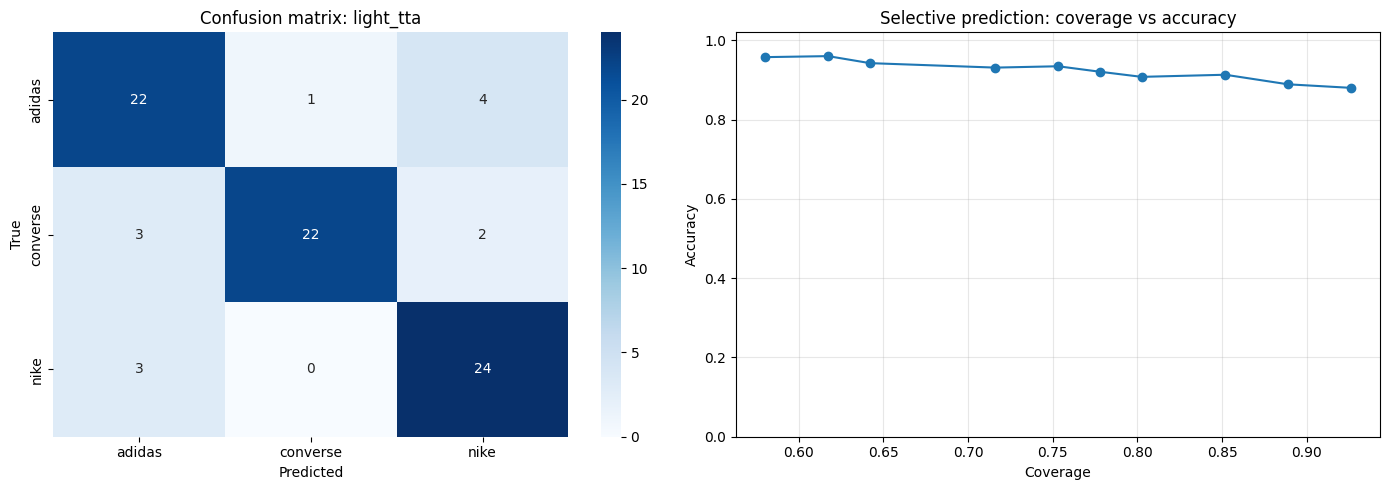

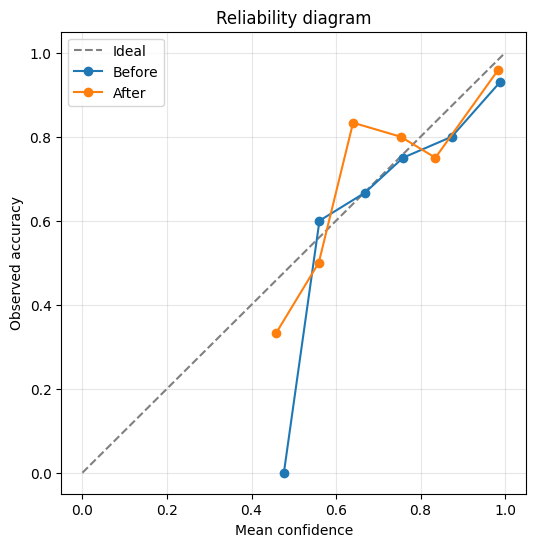

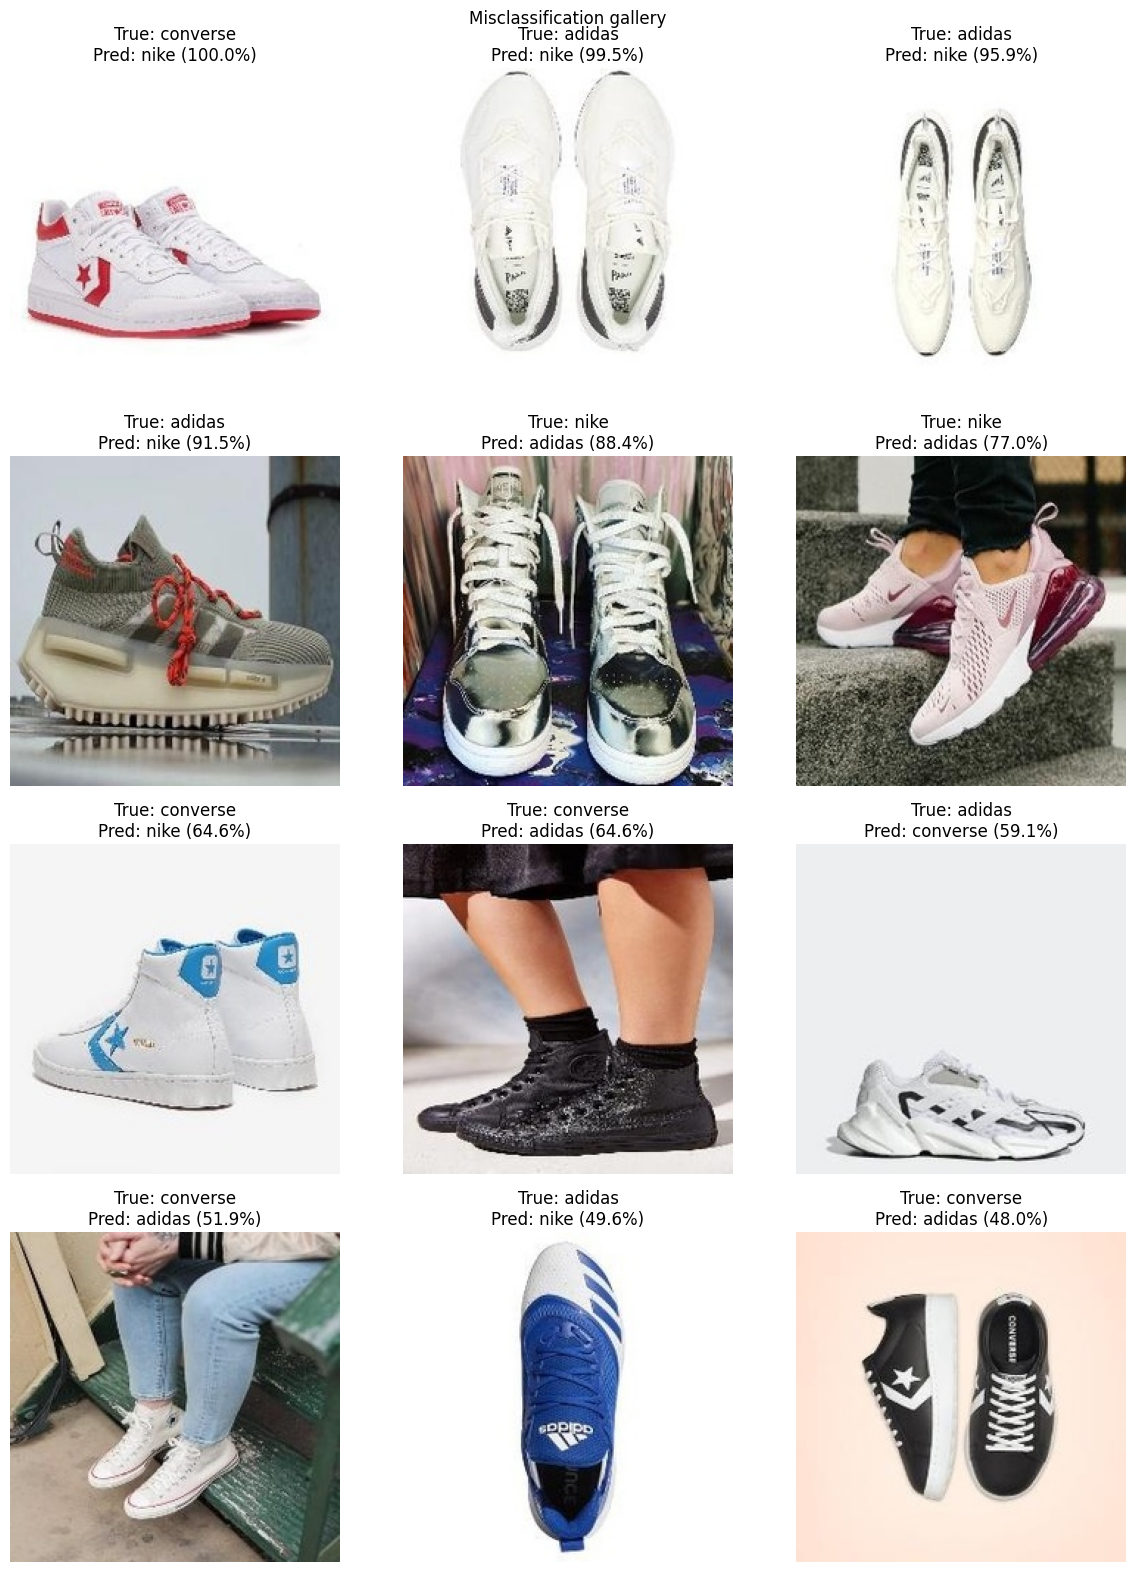

In [8]:
true_labels = selected_test_predictions["true_label"]
predicted_labels = selected_test_predictions["predicted_label"]
confusion_counts = confusion_matrix(true_labels, predicted_labels, labels=EXPECTED_CLASSES)
classification_report_frame = pd.DataFrame(classification_report(true_labels, predicted_labels, labels=EXPECTED_CLASSES, output_dict=True, zero_division=0)).T
figure, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(confusion_counts, annot=True, fmt="d", cmap="Blues", xticklabels=EXPECTED_CLASSES, yticklabels=EXPECTED_CLASSES, ax=axes[0])
axes[0].set_title(f"Confusion matrix: {selected_strategy}")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")
axes[1].plot(coverage_curve["coverage"], coverage_curve["selective_accuracy"], marker="o")
axes[1].set_title("Selective prediction: coverage vs accuracy")
axes[1].set_xlabel("Coverage")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.02)
axes[1].grid(alpha=0.3)
plt.tight_layout()
figure.savefig(OUTPUT_ROOT / "evaluation_overview.png", dpi=160, bbox_inches="tight")
plt.show()

def reliability_points(probabilities: np.ndarray, labels: np.ndarray, bins: int = ECE_BINS):
    confidence = probabilities.max(axis=1)
    prediction = probabilities.argmax(axis=1)
    rows = []
    for lower, upper in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        mask = (confidence > lower) & (confidence <= upper)
        if mask.any():
            rows.append({"confidence": confidence[mask].mean(), "accuracy": (prediction[mask] == labels[mask]).mean(), "count": int(mask.sum())})
    return pd.DataFrame(rows)
reliability_before = reliability_points(test_probabilities, test_labels)
reliability_after = reliability_points(calibrated_test_probabilities, test_labels)
figure, axis = plt.subplots(figsize=(6, 6))
axis.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Ideal")
axis.plot(reliability_before["confidence"], reliability_before["accuracy"], marker="o", label="Before")
axis.plot(reliability_after["confidence"], reliability_after["accuracy"], marker="o", label="After")
axis.set_xlabel("Mean confidence")
axis.set_ylabel("Observed accuracy")
axis.set_title("Reliability diagram")
axis.legend()
axis.grid(alpha=0.3)
figure.savefig(OUTPUT_ROOT / "reliability_diagram.png", dpi=160, bbox_inches="tight")
plt.show()

examples = misclassifications.head(12)
columns = 3
rows = max(1, int(np.ceil(len(examples) / columns)))
figure, axes = plt.subplots(rows, columns, figsize=(12, 4 * rows), squeeze=False)
for axis, (_, example) in zip(axes.flat, examples.iterrows()):
    axis.imshow(load_rgb(Path(example["image_path"])))
    axis.set_title(f"True: {example['true_label']}\nPred: {example['predicted_label']} ({example['confidence']:.1%})")
    axis.axis("off")
for axis in axes.flat[len(examples):]:
    axis.axis("off")
figure.suptitle("Misclassification gallery")
plt.tight_layout()
figure.savefig(OUTPUT_ROOT / "misclassification_gallery.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Save evaluation artifacts and recommendations

In [9]:
single_pass_predictions.to_csv(OUTPUT_ROOT / "single_pass_predictions.csv", index=False)
selected_test_predictions.to_csv(OUTPUT_ROOT / "tta_predictions.csv", index=False)
misclassifications.to_csv(OUTPUT_ROOT / "misclassifications.csv", index=False)
low_confidence_correct.to_csv(OUTPUT_ROOT / "low_confidence_correct.csv", index=False)
unstable_predictions.to_csv(OUTPUT_ROOT / "unstable_predictions.csv", index=False)
classification_report_frame.to_csv(OUTPUT_ROOT / "classification_report.csv")
pd.DataFrame(confusion_counts, index=EXPECTED_CLASSES, columns=EXPECTED_CLASSES).to_csv(OUTPUT_ROOT / "confusion_matrix.csv")
validation_comparison.to_csv(OUTPUT_ROOT / "validation_tta_comparison.csv", index=False)
test_comparison.to_csv(OUTPUT_ROOT / "test_strategy_comparison.csv", index=False)
robustness_summary.to_csv(OUTPUT_ROOT / "robustness_summary.csv", index=False)
coverage_curve.to_csv(OUTPUT_ROOT / "coverage_curve.csv", index=False)
with (OUTPUT_ROOT / "calibration_metrics.json").open("w", encoding="utf-8") as calibration_file:
    json.dump(calibration_metrics, calibration_file, indent=2)
evaluation_summary = {
    "model": str(MODEL_PATH),
    "selected_tta_strategy": selected_strategy,
    "selection_basis": "validation_macro_f1",
    "single_pass_test": metric_summary(single_pass_predictions),
    "selected_strategy_test": metric_summary(selected_test_predictions),
    "temperature": temperature,
    "unstable_test_images": len(unstable_predictions),
    "misclassified_test_images": len(misclassifications),
    "ultralytics_version": ultralytics_version,
    "pytorch_version": torch.__version__,
}
with (OUTPUT_ROOT / "evaluation_summary.json").open("w", encoding="utf-8") as summary_file:
    json.dump(evaluation_summary, summary_file, indent=2)

error_pairs = misclassifications.groupby(["true_label", "predicted_label"]).size().sort_values(ascending=False)
print("Most frequent error pairs:")
display(error_pairs.to_frame("count"))
print("Retraining recommendation: prioritize new, diverse images for the error pairs above and unstable images; do not retrain on held-out test images.")
print(f"Artifacts saved to: {OUTPUT_ROOT}")

Most frequent error pairs:


count
true_label predicted_label       
adidas     nike                 4
nike       adidas               3
converse   adidas               3
           nike                 2
adidas     converse             1

Retraining recommendation: prioritize new, diverse images for the error pairs above and unstable images; do not retrain on held-out test images.
Artifacts saved to: C:\my-project\shoe-brand-classifier\modeling\runs\training\advanced_evaluation
